In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [7]:
# 1. Load Dataset
df = pd.read_csv("Feature_Engineering_DecisionTree_RF_Dataset.csv")

print("First 5 rows:\n", df.head())
print("\nInfo:\n")
print(df.info())

First 5 rows:
    Age    Income  Experience  Credit_Score  Total_Spending  Purchase_Count  \
0   60   49184.0           1         581.0           33098              58   
1   22   27811.0           5         523.0           31495             130   
2   34  137757.0          37         584.0            1851             195   
3   41   46793.0           5         689.0           13676              92   
4   27  119230.0           5         865.0           39427             161   

   Login_Hour  Complaints        City      Education Job_Category  \
0           5           3        Pune       Graduate    Marketing   
1          20           0        Pune       Graduate    Marketing   
2           6          13  Chandigarh  Post Graduate      Finance   
3          12          19  Chandigarh       Graduate   Healthcare   
4          20          11        Pune       Graduate           IT   

  Joining_Date  Target  
0   2021-06-18       0  
1   2021-05-29       0  
2   2016-10-29       0  
3

In [10]:
# 2. Feature Engineering
# Handle missing values
df.fillna(df.mean(numeric_only=True), inplace=True)
# print(df)

In [3]:
# Encode categorical columns
le = LabelEncoder()
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col])
    print(col)

NameError: name 'LabelEncoder' is not defined

In [15]:
# Feature scaling (optional but good practice)
scaler = StandardScaler()

# Separate features & target
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

X = scaler.fit_transform(X)
print(X)

[[ 1.29196935 -1.33235626 -1.63127134 ... -1.26612722  1.39294109
   0.91457991]
 [-1.59250274 -1.6654505  -1.29759852 ... -1.26612722  1.39294109
   0.90289109]
 [-0.68161682  0.0480375   1.37178403 ...  0.9746134  -0.74844596
  -0.37118991]
 ...
 [ 1.44378367 -1.23256669  1.12152942 ... -0.14575691  0.67914541
   0.42754589]
 [-1.59250274 -1.27148198 -1.38101673 ... -1.26612722  1.39294109
  -0.74523204]
 [-0.5298025   0.68629798  0.70443839 ... -1.26612722  0.67914541
  -1.18940706]]


In [13]:
# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [14]:
# 4. Decision Tree
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("\n🌳 Decision Tree Results")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))


🌳 Decision Tree Results
Accuracy: 0.9368932038834952
Confusion Matrix:
 [[159   4]
 [  9  34]]


First 5 rows:
    Age    Income  Experience  Credit_Score  Total_Spending  Purchase_Count  \
0   60   49184.0           1         581.0           33098              58   
1   22   27811.0           5         523.0           31495             130   
2   34  137757.0          37         584.0            1851             195   
3   41   46793.0           5         689.0           13676              92   
4   27  119230.0           5         865.0           39427             161   

   Login_Hour  Complaints        City      Education Job_Category  \
0           5           3        Pune       Graduate    Marketing   
1          20           0        Pune       Graduate    Marketing   
2           6          13  Chandigarh  Post Graduate      Finance   
3          12          19  Chandigarh       Graduate   Healthcare   
4          20          11        Pune       Graduate           IT   

  Joining_Date  Target  
0   2021-06-18       0  
1   2021-05-29       0  
2   2016-10-29       0  
3

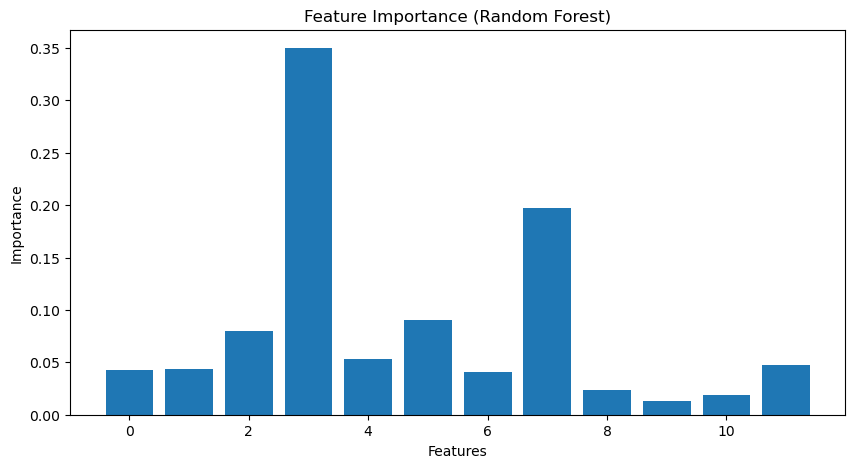

In [5]:
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import accuracy_score, confusion_matrix

# -------------------------------
# 1. Load Dataset
# -------------------------------
df = pd.read_csv("Feature_Engineering_DecisionTree_RF_Dataset.csv")

print("First 5 rows:\n", df.head())
print("\nInfo:\n")
print(df.info())

# -------------------------------
# 2. Feature Engineering
# -------------------------------

# Handle missing values
df.fillna(df.mean(numeric_only=True), inplace=True)

# Encode categorical columns
le = LabelEncoder()
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col])

# Feature scaling (optional but good practice)
scaler = StandardScaler()

# Separate features & target
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

X = scaler.fit_transform(X)

# -------------------------------
# 3. Train-Test Split
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -------------------------------
# 4. Decision Tree
# -------------------------------
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("\n🌳 Decision Tree Results")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

# -------------------------------
# 5. Random Forest
# -------------------------------
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("\n🌲 Random Forest Results")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

# -------------------------------
# 6. Feature Importance (Bonus)
# -------------------------------
importances = rf.feature_importances_

plt.figure(figsize=(10,5))
plt.bar(range(len(importances)), importances)
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()